# Same-initialization student distillation — results

Live analysis of `outputs/students/`, scoped by default to the July 2026 **same-initialization** treatment for **`dog`** on the original **`pythia-160m`** base: teacher and student share the `pythia-160m` checkpoint, the numbers are `ex10-20_prefix` (100k candidate pool, 10 000 trained rows), and both fine-tuning seeds are 1. Section 5 steps aside to the `cat` runs — the only base with a matched PolyPythia re-run — to isolate a base-model effect. Section 6 holds the teacher and student fixed and varies only the **number-generation mode** (free-gen baseline vs. the spliced-prompt and constrained-decoding variants).

The notebook visualizes run coverage, held-out transfer versus trained controls, student-epoch dose response, seed-matched teacher→student association, teacher hyperparameters, specificity/OOD behavior, the top configurations, a base-model comparison, and the number-generation-mode comparison.

> **Uncertainty warning.** Current treatment summaries contain one student seed. Persisted across-seed CIs therefore collapse to the point estimate. Spread across teacher configurations below is descriptive, not repeated-seed uncertainty.

> **Student-eval coverage.** The `dog` `pythia-160m` students were scored on `test` and `storytelling` only — the `off_topic`, `validation`, and `dislike` student prompt sets were not run for this base. Panels that depend on those sets (the specificity/off-topic view) therefore render empty; the teacher-side association still works because the teacher's own `validation` score is read directly. Backfill the student evals to repopulate them.

## Setup and artifact loader

Run from the repo root with `uv run --group analysis jupyter lab`. The loader joins every student to its training manifest and to the exact teacher seed that generated its number dataset.

In [ ]:
from __future__ import annotations
import json, re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from subliminal_learning.analysis import frames, plots as aplots
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
STUDENTS_ROOT = OUTPUT_ROOT / "students"
# Sections 1-4 scope: dog on the original pythia-160m base, teacher/ft seed 1. (Section 5 reaches into cat directly.)
SAME_INIT_ANIMAL, SAME_INIT_MODEL, TEACHER_SEED, STUDENT_SEED = "dog", "pythia-160m", 1, 1
# Dataset dirs carry a candidate-pool suffix (_n40k / _n100k); both train 10 000 rows. dog uses the 100k prefix pool.
LABEL = {"ex10-20_prefix_n100k":"prefix (100k pool)", "ex10-20_prefix_n40k":"prefix (40k pool)",
         "ex10-20_full10":"full10", "ex10-20_full10_3digit":"full10, 3-digit",
         # Number-generation modes compared in Section 6 (see there for the DGP caveat on the constrained pool).
         "ex10-20_prefix_n100k_spliced":"prefix, spliced prompts", "intro-u10_prefix_n10k":"constrained intro ≤10"}
COLOR = {"ex10-20_prefix_n100k":"#4c78a8", "ex10-20_prefix_n40k":"#4c78a8",
         "ex10-20_full10":"#f58518", "ex10-20_full10_3digit":"#54a24b",
         "ex10-20_prefix_n100k_spliced":"#b279a2", "intro-u10_prefix_n10k":"#9d755d"}
set_plot_style(dpi=115, grid_alpha=0.25, hide_spines=True)
print("output_root:", OUTPUT_ROOT)

In [ ]:
TEACHER_DIR_RE = re.compile(r"^teacher-(?P<nbase>.+)$")
TAGSEED_RE = re.compile(r"^(?P<tag>ep\d+_lr[^_]+_r\d+a\d+)_tseed(?P<seed>\d+)$")

def read(path): return json.loads(path.read_text())

def metric_rows(doc, meta, teacher_sets=None):
    teacher_sets = teacher_sets or {}
    return [{**meta, "set":s["prompt_set"], "scoring":s.get("scoring"), "n_prompts":s.get("n_prompts"),
             "p":s.get("p_target_mean"), "rank":s.get("rank_mean"), "base_p":s.get("base_p_target"),
             "teacher_p":teacher_sets.get(s["prompt_set"], {}).get("p_target")}
            for s in doc.get("summaries", [])]

def load_treatments():
    rows = []
    n_missing_manifest = n_skipped = 0
    for p in sorted(STUDENTS_ROOT.rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT).parts
        if not rel or rel[0] == "controls": continue  # controls handled by load_controls
        if len(rel) != 7: n_skipped += 1; continue
        animal, model, teacher_dir, tagseed, dataset, student_tag, _ = rel
        mt = TEACHER_DIR_RE.fullmatch(teacher_dir); ms = TAGSEED_RE.fullmatch(tagseed)
        if not mt or not ms: n_skipped += 1; continue
        teacher_tag, tseed = ms["tag"], int(ms["seed"])
        numbers_base = mt["nbase"]
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        manifest_path = p.parent / f"ftseed{seeds[0]}" / "train_manifest.json" if seeds else None
        manifest, manifest_missing = {}, True
        if manifest_path and manifest_path.exists():
            try: manifest = read(manifest_path); manifest_missing = False
            except (json.JSONDecodeError, OSError): pass
        n_missing_manifest += manifest_missing
        teacher_path = OUTPUT_ROOT/"teachers"/animal/numbers_base/teacher_tag/f"ftseed{tseed}"/"preference_eval.json"
        teacher_doc = read(teacher_path) if teacher_path.exists() else {}
        tsets = teacher_doc.get("sets") or {}
        def tp(name):
            s = tsets.get(name); return s.get("p_target") if isinstance(s, dict) else None
        meta = {"config_id":str(p.parent), "animal":animal, "model":model, "numbers_base":numbers_base,
                "teacher_tag":teacher_tag, "teacher_seed":tseed, "dataset":dataset, "student_tag":student_tag,
                "student_seeds":seeds, "same_init":None if manifest_missing else (numbers_base == model and seeds == (tseed,) and not manifest.get("cross_base", False)),
                # Teacher association signal read straight from the teacher eval (independent of which prompt sets the
                # student was scored on) — the original pythia-160m students share only `test`/`storytelling` with the teacher.
                "teacher_sig_validation":tp("validation"), "teacher_sig_test":tp("test"),
                "n_train":manifest.get("n_train_rows"), "loss":manifest.get("final_train_loss"), "steps":manifest.get("n_train_steps"),
                **frames.parse_param_tag(teacher_tag,"teacher"), **frames.parse_param_tag(student_tag,"student")}
        rows += metric_rows(doc, meta, teacher_doc.get("sets"))
    return pd.DataFrame(rows), n_missing_manifest, n_skipped

def load_controls():
    rows = []
    for p in sorted((STUDENTS_ROOT/"controls").rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT/"controls").parts
        if rel and rel[0] == "base":
            if len(rel) != 8 or rel[5] != "eval": continue
            source, model, teacher_dir, dataset, student_tag, _, animal, _ = rel
        else:
            if len(rel) != 7 or rel[4] != "eval": continue
            source, model, dataset, student_tag, _, animal, _ = rel
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        meta = {"config_id":str(p.parent), "source":source, "animal":animal, "model":model, "dataset":dataset,
                "student_tag":student_tag, "student_seeds":seeds, **frames.parse_param_tag(student_tag,"student")}
        rows += metric_rows(doc, meta)
    return pd.DataFrame(rows)

treatments_all, n_missing_manifest, n_skipped = load_treatments()
controls_all = load_controls()
# Sections 1-4: dog + original pythia-160m, same-init, teacher/ft seed 1.
same = treatments_all[treatments_all.same_init.eq(True) & treatments_all.animal.eq(SAME_INIT_ANIMAL) & treatments_all.model.eq(SAME_INIT_MODEL) &
                      treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,))].copy()
controls = (controls_all[controls_all.animal.eq(SAME_INIT_ANIMAL) & controls_all.model.eq(SAME_INIT_MODEL) &
                         controls_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,))].copy()
            if len(controls_all) else controls_all)
assert len(same), "selected same-initialization slice is empty"

META = ["config_id","animal","model","teacher_tag","teacher_seed","dataset","student_tag","teacher_epochs","teacher_lr",
        "teacher_rank","teacher_alpha","teacher_sig_validation","teacher_sig_test","student_epochs","student_lr",
        "student_rank","student_alpha","n_train","loss","steps"]
wide = same.drop_duplicates("config_id")[META].set_index("config_id")
for value, prefix in [("p","student_"),("teacher_p","teacher_"),("base_p","untuned_"),("rank","rank_")]:
    wide = wide.join(same.pivot(index="config_id", columns="set", values=value).add_prefix(prefix))
wide = wide.reset_index()
wide["teacher_lora"] = wide.apply(lambda x:f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)
wide["lineage"] = wide.apply(lambda x:f"{x.teacher_tag}|t{x.teacher_seed}|{x.dataset}", axis=1)
# Optional student prompt sets. The original pythia-160m students carry only `test` and `storytelling`; ensure the
# richer per-set columns exist (as NaN) so panels degrade to empty instead of raising on a missing column.
for _pref in ("student_", "teacher_", "untuned_", "rank_"):
    for _set in ("test", "off_topic", "validation", "storytelling"):
        _col = f"{_pref}{_set}"
        if _col not in wide.columns: wide[_col] = np.nan
wide["test_minus_offtopic"] = wide.student_test - wide.student_off_topic
# Teacher signal: prefer the teacher's own `test`, else its `validation`, whichever the teacher eval actually scored.
TEACHER_SIGNAL_SET = "test" if wide.teacher_sig_test.notna().any() else "validation"
wide["teacher_signal"] = wide[f"teacher_sig_{TEACHER_SIGNAL_SET}"]

if len(controls):
    cm = controls.drop_duplicates("config_id")[["config_id","source","model","dataset","student_tag","student_epochs"]].set_index("config_id")
    controls_wide = cm.join(controls.pivot(index="config_id", columns="set", values="p").add_prefix("student_")).reset_index()
else: controls_wide = pd.DataFrame()
if n_missing_manifest: print(f"{n_missing_manifest} runs missing train_manifest.json — excluded")
if n_skipped: print(f"{n_skipped} dirs skipped by layout/regex filters")
print(f"{len(wide)} same-init configs ({SAME_INIT_ANIMAL} / {SAME_INIT_MODEL}); {wide.lineage.nunique()} teacher/dataset lineages; {len(controls_wide)} controls")
print("sets:", sorted(same["set"].unique()))

## 1. Inventory and held-out transfer

A config is one `(teacher HP × number mode × student epoch)` result. `test` is the main held-out preference metric. Control markers are trained `base`/`rng` students, now backfilled at every student dose and plotted at their own epoch; the matched-Δ table below compares each number mode's treatment against the **dose-matched** (1-epoch) control.

The transfer chart is shown in **two rows**:

- **Row 1 — all collected configs.** Every completed config, one box per number mode × student dose.
- **Row 2 — shared cells (apples-to-apples).** The three number-generation modes — `prefix`, `prefix-spliced`, and `constrained-intro` — restricted to the teacher-HP cells present in **all three** modes, so every box aggregates over an identical config set.

A config can only train a same-init student if its teacher produced **≥ 10k usable number sequences**. Constrained decoding (`intro-u10`) guarantees valid output (keep-rate 1.0), so it yields a full pool for every teacher; free-gen (`ex10-20 prefix`) keep-rates vary and many degenerate (high-LR) teachers fall below 10k. Constrained students were trained on only a pre-selected subset of teachers (those correlated with stronger transfer), all of which also have free-gen students — so row 1's constrained box is drawn from that biased subset. Row 2's shared-cell restriction is what makes the mode comparison statistically fair.

student_epochs,1,2,5,10
prefix (100k pool),102,102,102,102
"prefix, spliced prompts",102,102,102,102
constrained intro ≤10,22,22,22,22


missing teacher scores by set:


set
test    904
Name: missing, dtype: int64

teacher association signal: validation
training rows: [np.int64(10000)]


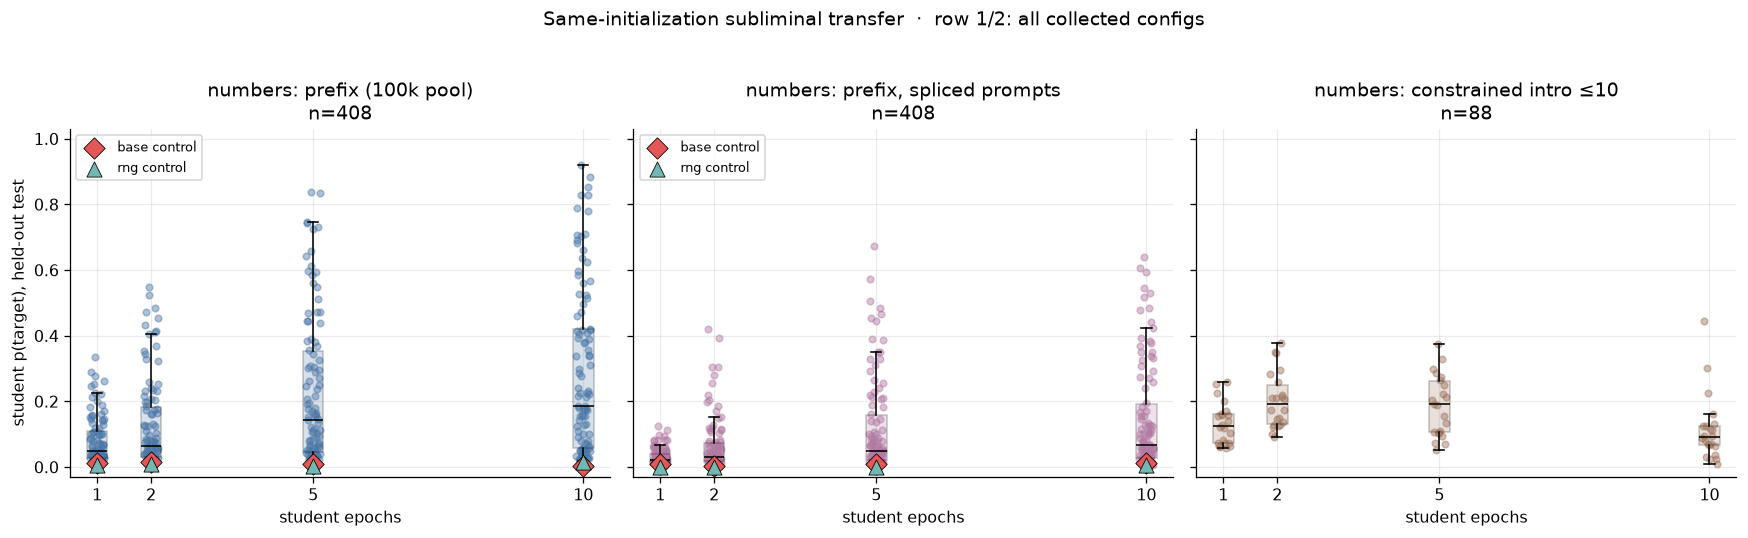

,n,treatment mean,treatment median,base student,mean Δ vs base,rng student,mean Δ vs rng
numbers,,,,,,,
prefix (100k pool),102,0.081,0.048,0.012,0.069,0.006,0.075
"prefix, spliced prompts",102,0.031,0.021,0.009,0.022,0.001,0.030
constrained intro ≤10,22,0.132,0.125,nan,nan,nan,nan


trained-student teacher-HP cells per mode: {'ex10-20_prefix_n100k': 102, 'ex10-20_prefix_n100k_spliced': 102, 'intro-u10_prefix_n10k': 22} |  shared across all 3: 22


In [3]:
coverage = pd.crosstab(wide.dataset, wide.student_epochs)
coverage.index = [LABEL.get(x,x) for x in coverage.index]
display(coverage.style.set_caption("Completed same-init configs"))
assert same.duplicated(["config_id","set"]).sum() == 0
print("missing teacher scores by set:")
display(same[same.teacher_p.isna()].groupby("set").size().rename("missing"))
print("teacher association signal:", TEACHER_SIGNAL_SET)
print("training rows:", sorted(wide.n_train.dropna().unique()))

def transfer_boxplots(df, datasets, *, suptitle, epochs=None):
    """Per-dataset held-out-test boxplots vs student dose (the Section-1 chart); reused across rows 1-3."""
    epochs = sorted(df.student_epochs.unique()) if epochs is None else epochs
    n = max(len(datasets), 1)
    fig, axs = plt.subplots(1,n,figsize=(5.1*n,4.5),sharey=True,squeeze=False)
    for ax, ds in zip(axs.ravel(),datasets):
        sub = df[df.dataset.eq(ds)]
        groups = [(ep,sub.loc[sub.student_epochs.eq(ep),"student_test"].dropna().values) for ep in epochs]
        groups = [(ep,v) for ep,v in groups if len(v)]
        if groups:
            ax.boxplot([v for _,v in groups],positions=[ep for ep,_ in groups],widths=.38,patch_artist=True,showfliers=False,
                       boxprops={"facecolor":COLOR.get(ds,"C0"),"alpha":.22},medianprops={"color":"black"})
            for ep,v in groups:
                jitter = np.linspace(-.13,.13,len(v)) if len(v)>1 else [0]
                ax.scatter(ep+jitter,v,s=17,alpha=.45,color=COLOR.get(ds,"C0"))
        if len(controls_wide):
            # Controls are backfilled at every student dose; plot each at its own epoch (dose-matched to the treatment).
            for source,marker,color in [("base","D","#e45756"),("rng","^","#72b7b2")]:
                cc=controls_wide[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source)].dropna(subset=["student_test"])
                if len(cc): ax.scatter(cc.student_epochs,cc.student_test,marker=marker,s=90,color=color,edgecolor="black",lw=.5,zorder=5,label=f"{source} control")
        base=sub.untuned_test.dropna()
        if len(base): ax.axhline(base.iloc[0],color=".35",ls=":",label="untuned base")
        ax.set(title=f"numbers: {LABEL.get(ds,ds)}\nn={len(sub)}",xlabel="student epochs",xticks=epochs,ylim=(-.03,1.03))
        if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=8,loc="upper left")  # skip empty legend (e.g. lineages with no controls/untuned baseline)
    axs[0,0].set_ylabel("student p(target), held-out test")
    fig.suptitle(suptitle,y=1.03); plt.tight_layout(); plt.show()

# Row 1 — every collected config, one box per number mode x student dose.
transfer_boxplots(wide, sorted(wide.dataset.unique()),
                  suptitle="Same-initialization subliminal transfer  ·  row 1/2: all collected configs")

# Matched Δ at 1 epoch: treatment@ep1 vs the DOSE-MATCHED (ep1) base/rng control. Controls now exist at every
# dose, so restrict to student_epochs==1 here; the assert then guards genuine duplicates (same source/dataset/dose).
matched=[]
for ds,sub in wide[wide.student_epochs.eq(1)].groupby("dataset"):
    row={"numbers":LABEL.get(ds,ds),"n":len(sub),"treatment mean":sub.student_test.mean(),"treatment median":sub.student_test.median()}
    for source in ("base","rng"):
        cc=(controls_wide[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source)&controls_wide.student_epochs.eq(1)]
            if len(controls_wide) else pd.DataFrame())
        v=cc["student_test"].dropna() if len(cc) else pd.Series(dtype=float)
        assert len(v)<=1, f"multiple {source} ep1 controls for dataset {ds}: {v.tolist()}"
        row[f"{source} student"]=v.iloc[0] if len(v) else np.nan
        row[f"mean Δ vs {source}"]=row["treatment mean"]-row[f"{source} student"]
    matched.append(row)
display(pd.DataFrame(matched).set_index("numbers").style.format({c:"{:.3f}" for c in pd.DataFrame(matched).columns if c not in ("numbers","n")}))

# Number-generation modes compared in row 2 (same three as Section 6). Constrained decoding (intro-u10) students
# were trained only on a pre-selected subset of teachers correlated with stronger transfer, so row 1's constrained
# box is upward-biased. Row 2 restricts all three modes to the teacher-HP cells shared by every mode.
MODE_DATASETS    = ["ex10-20_prefix_n100k", "ex10-20_prefix_n100k_spliced", "intro-u10_prefix_n10k"]
CONSTRAINED_MODE = "intro-u10_prefix_n10k"
_mode_tags = {ds: set(wide.loc[wide.dataset.eq(ds), "teacher_tag"]) for ds in MODE_DATASETS}
SHARED_TAGS = set.intersection(*_mode_tags.values()) if _mode_tags else set()
print("trained-student teacher-HP cells per mode:", {ds: len(t) for ds, t in _mode_tags.items()},
      f"|  shared across all 3: {len(SHARED_TAGS)}")

**Row 2 — shared cells (apples-to-apples mode comparison).** Restricts `prefix`, `prefix-spliced`, and `constrained-intro` to the teacher-HP cells present in **all three** modes, so every box aggregates over an identical config set. This removes the selection bias from constrained decoding, whose students were trained only on teachers pre-selected for stronger transfer.

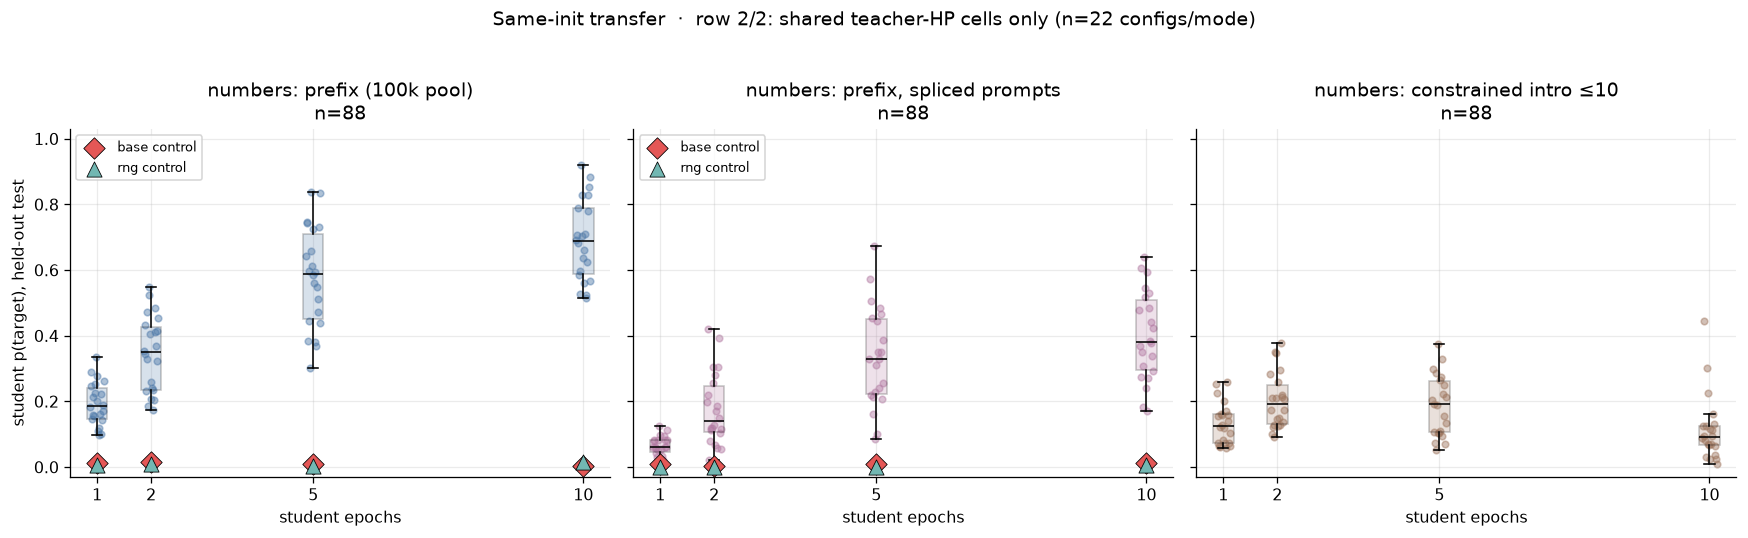

In [4]:
# Row 2 — the same boxplots restricted to teacher-HP cells present in ALL THREE number-gen modes, so prefix,
# prefix-spliced, and constrained-intro aggregate over an identical config set (removes the constrained-cell
# selection bias). This is the apples-to-apples version of row 1's mode comparison.
if SHARED_TAGS:
    row2 = wide[wide.dataset.isin(MODE_DATASETS) & wide.teacher_tag.isin(SHARED_TAGS)]
    transfer_boxplots(row2, MODE_DATASETS,
                      suptitle=f"Same-init transfer  ·  row 2/2: shared teacher-HP cells only "
                               f"(n={len(SHARED_TAGS)} configs/mode)")
else:
    print("no teacher-HP cell is shared across all three number-gen modes - row 2 skipped")

## 2. Student dose and teacher → student transfer

Dose-response includes only lineages completed at 1, 2, and 5 epochs. Shaded intervals describe cross-config variation, not seed uncertainty. The teacher signal is read straight from the source teacher's own eval — teacher `test` when available, otherwise teacher `validation` (the teacher artifacts carry no `test` set); student `test` remains the outcome. Spearman's ρ is associative, not causal.

In [ ]:
# `epochs` = the student-dose axis (was previously an undefined global on a clean run).
epochs = sorted(wide.student_epochs.unique())

complete = wide.groupby("lineage").student_epochs.agg(lambda x:{1,2,5}.issubset(set(x)))
paired = wide[wide.lineage.isin(complete[complete].index)]
print(f"{paired.lineage.nunique()} complete lineages / {len(paired)} students")
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
for ax,(metric,label) in zip(axs,[("student_test","held-out test"),("student_off_topic","off-topic"),("student_storytelling","storytelling")]):
    aplots.dose_response(ax,paired,x="student_epochs",y=metric,group="dataset",colors=COLOR,labels=LABEL,ci=True)
    ax.set(xlabel="student epochs",ylabel=f"{label} p(target)",xticks=[1,2,5],ylim=(-.03,1.03)); ax.legend(fontsize=8)
fig.suptitle("Student training-dose response — complete lineages",y=1.03); plt.tight_layout(); plt.show()

fig,axs=plt.subplots(1,len(epochs),figsize=(5*len(epochs),4.3),sharex=True,sharey=True,squeeze=False)
for ax,ep in zip(axs.ravel(),epochs):
    sub=wide[wide.student_epochs.eq(ep)].dropna(subset=["teacher_signal","student_test"])
    for ds,d in sub.groupby("dataset"): ax.scatter(d.teacher_signal,d.student_test,s=32,alpha=.65,color=COLOR.get(ds),label=LABEL.get(ds,ds))
    rho,p=spearmanr(sub.teacher_signal,sub.student_test) if len(sub)>2 else (np.nan,np.nan); ax.plot([0,1],[0,1],color=".5",ls=":")
    ax.text(.03,.97,f"n={len(sub)}\nρ={rho:.2f}, p={p:.2g}",transform=ax.transAxes,va="top",bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"})
    ax.set(title=f"student epochs={ep}",xlabel=f"teacher p(target), {TEACHER_SIGNAL_SET}",xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend(fontsize=8,loc="lower right")
axs[0,0].set_ylabel("student p(target), test"); fig.suptitle(f"Seed-matched teacher {TEACHER_SIGNAL_SET} → student test",y=1.03); plt.tight_layout(); plt.show()

## 3. Teacher hyperparameter surface

Edit the dataset choice. One figure per animal (here just `dog`); **rows = student epochs**
(ascending), columns = teacher LR (ascending), so reading down a column shows how the same
teacher-HP surface sharpens with student dose. Within a figure each populated cell is a single
teacher run — a duplicate-key assert on `(animal, student_epochs, teacher_epochs, teacher_lora,
teacher_lr)` guarantees no pooling across runs. Rank/alpha and learning rate remain explicit.

In [ ]:
PRIMARY_DATASET, PRIMARY_STUDENT_EPOCH = "ex10-20_prefix_n100k", 5  # PRIMARY_STUDENT_EPOCH still pins §6's mode comparison
hp=wide[wide.dataset.eq(PRIMARY_DATASET)]
assert len(hp)
DUP_KEYS=["animal","student_epochs","teacher_epochs","teacher_lora","teacher_lr"]
assert not hp.duplicated(DUP_KEYS).any(), \
    f"duplicate teacher-HP keys would pool multiple runs per heatmap cell: {hp[hp.duplicated(DUP_KEYS,keep=False)][DUP_KEYS].to_dict('records')}"
loras=sorted(hp.teacher_lora.unique(),key=lambda x:tuple(map(int,re.findall(r"\d+",x))))
for animal in sorted(hp.animal.unique()):
    ha=hp[hp.animal.eq(animal)]
    _ = aplots.facet_grid_heatmaps(
        ha, row="teacher_epochs", col="teacher_lora", val="student_test",
        row_facet="student_epochs", col_facet="teacher_lr",
        orders={"teacher_lora": loras}, mid=0.55, cmap="viridis", vmin=0, vmax=1,
        cbar_label="student test p(target)",
        row_facet_label=lambda sep: f"student ep={sep}",
        col_facet_label=lambda lr: f"teacher lr={lr:.0e}",
        title=f"Teacher HP → transfer | {animal} | {LABEL.get(PRIMARY_DATASET)} numbers | rows = student epochs")

## 4. Specificity, OOD behavior, and ranked configs

High `test` with low `off_topic` is more specific. Storytelling is sampled and may be read as OOD generalization or leakage. The table's transparent ranking score is `test − off_topic`, not a definitive objective.

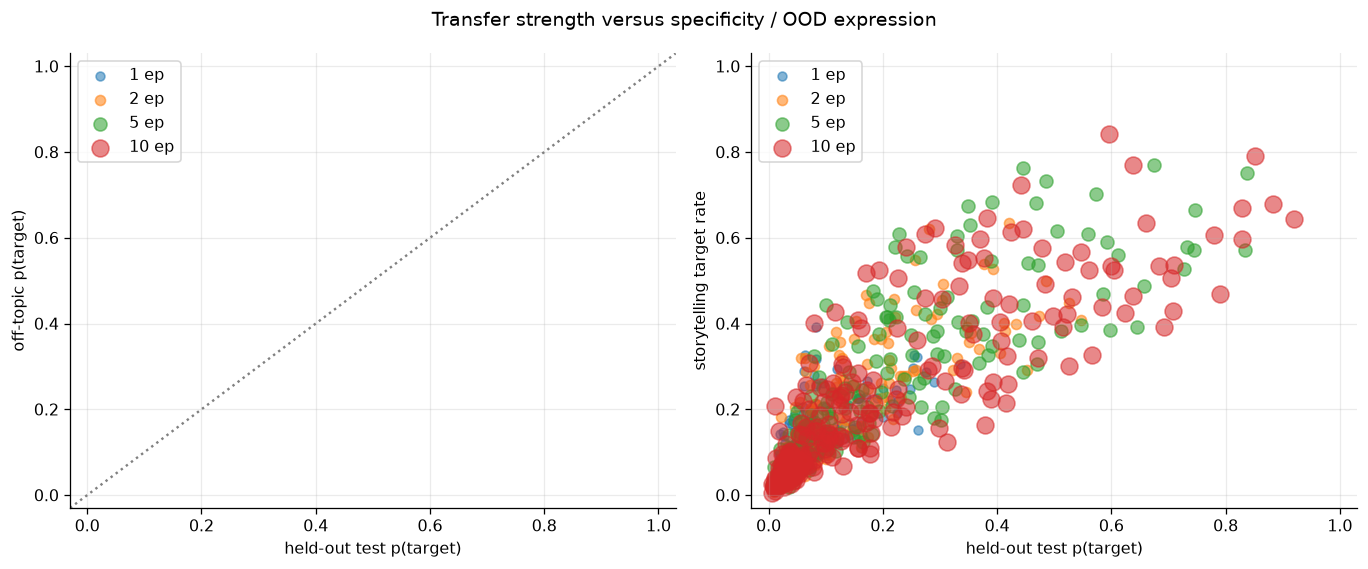

,teacher_tag,dataset,student ep,teacher validation,student_test,student_validation,student_off_topic,student_storytelling,test_minus_offtopic,test rank,loss
284,ep20_lr1e-4_r16a32,ex10-20_prefix_n100k,10,1.000,0.920,nan,nan,0.645,nan,1.0,1.781
892,ep7_lr5e-4_r8a8,ex10-20_prefix_n100k,10,1.000,0.883,nan,nan,0.679,nan,1.0,1.908
756,ep5_lr5e-4_r8a16,ex10-20_prefix_n100k,10,1.000,0.852,nan,nan,0.791,nan,1.0,1.781
287,ep20_lr1e-4_r16a32,ex10-20_prefix_n100k,5,1.000,0.838,nan,nan,0.751,nan,1.0,2.017
895,ep7_lr5e-4_r8a8,ex10-20_prefix_n100k,5,1.000,0.835,nan,nan,0.572,nan,1.0,1.985
716,ep5_lr2e-4_r64a64,ex10-20_prefix_n100k,10,1.000,0.828,nan,nan,0.671,nan,1.0,1.985
296,ep20_lr1e-4_r32a32,ex10-20_prefix_n100k,10,1.000,0.828,nan,nan,0.598,nan,1.0,1.756
48,ep10_lr1e-4_r64a64,ex10-20_prefix_n100k,10,1.000,0.791,nan,nan,0.468,nan,1.0,1.880
744,ep5_lr5e-4_r16a16,ex10-20_prefix_n100k,10,1.000,0.780,nan,nan,0.606,nan,1.0,1.811
39,ep10_lr1e-4_r32a64,ex10-20_prefix_n100k,5,1.000,0.746,nan,nan,0.664,nan,1.0,2.040


,count,mean,median
student_epochs,,,
1,226,0.063,0.036
2,226,0.108,0.058
5,226,0.174,0.094
10,226,0.206,0.114


Overall teacher validation ↔ student test association: ρ=0.761, p=1.32e-171
Best test−off-topic: ep20_lr1e-4_r16a32, prefix (100k pool), student ep=10, test=0.920, off-topic=nan, storytelling=0.645


In [7]:
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,y,label in [(axs[0],"student_off_topic","off-topic p(target)"),(axs[1],"student_storytelling","storytelling target rate")]:
    for ep,sub in wide.groupby("student_epochs"): ax.scatter(sub.student_test,sub[y],s=22+9*ep,alpha=.55,label=f"{ep} ep")
    ax.set(xlabel="held-out test p(target)",ylabel=label,xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend()
axs[0].axline((0,0),slope=1,color=".5",ls=":"); fig.suptitle("Transfer strength versus specificity / OOD expression"); plt.tight_layout(); plt.show()

cols=["teacher_tag","dataset","student_epochs","teacher_signal","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","rank_test","loss"]
top=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False)[cols].head(25).rename(columns={"student_epochs":"student ep","rank_test":"test rank","teacher_signal":f"teacher {TEACHER_SIGNAL_SET}"})
formats={c:"{:.3f}" for c in [f"teacher {TEACHER_SIGNAL_SET}","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","loss"]}; formats["test rank"]="{:.1f}"
display(top.style.format(formats))

best=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False).iloc[0]
dose=wide.groupby("student_epochs").student_test.agg(["count","mean","median"])
rho,p=spearmanr(wide.teacher_signal,wide.student_test,nan_policy="omit")
display(dose.style.format({"mean":"{:.3f}","median":"{:.3f}"}))
print(f"Overall teacher {TEACHER_SIGNAL_SET} ↔ student test association: ρ={rho:.3f}, p={p:.3g}")
print(f"Best test−off-topic: {best.teacher_tag}, {LABEL.get(best.dataset,best.dataset)}, student ep={best.student_epochs:g}, test={best.student_test:.3f}, off-topic={best.student_off_topic:.3f}, storytelling={best.student_storytelling:.3f}")

## 5. Does the base checkpoint set same-init transfer strength? (`cat`, `pythia-160m` vs `pythia-160m-data-seed1`)

Sections 1–4 are scoped to `dog` + the original `pythia-160m`. This section steps sideways to the **`cat`** runs, the only subject where the original `pythia-160m` has a matched PolyPythia re-run (`data-seed1`) to compare against. The question: is same-init transfer strength a property of the *base checkpoint* — or of what happened to be run? The two bases weren't run identically (`data-seed1` also spans `full10`/`full10_3digit`, and its prefix numbers were drawn from a larger candidate pool), so pooling them naively is apples-to-oranges.

This section makes the comparison **fair** by matching everything mechanical and letting only the base model vary:

- **number mode** fixed to the `ex10-20_prefix` template — both bases train on **10 000** prefix rows (the candidate pools differ, 40k for the original vs 100k for `data-seed1`, but the trained row count and format are identical),
- **teacher HP grid** intersected (only teacher configs run for *both* bases),
- **student dose** compared epoch-by-epoch,
- **student LoRA** identical (`lr1e-4_r8a32`), **teacher seed 1 / ft seed 1**, both **same-init** (student initialized from the same checkpoint that generated its numbers).

The two right-hand panels are **controls**: the teacher's own trait strength (are the teachers equally good?) and the student's final train loss (did `pythia-160m` just fail to fit the numbers?). If both controls match, the residual gap is a genuine base-model / pretraining-run effect on the covert number→preference channel.

In [ ]:
# Compare same-init transfer for two bases (cat), matched on everything mechanical so only the base model differs.
CMP_ANIMAL = "cat"   # the only subject with both the original pythia-160m and its data-seed1 re-run
CMP_BASES = ["pythia-160m", "pythia-160m-data-seed1"]
BASE_NAME = {"pythia-160m":"pythia-160m (original)", "pythia-160m-data-seed1":"data-seed1"}
BASE_C    = {"pythia-160m":"#e45756", "pythia-160m-data-seed1":"#4c78a8"}
CMP_MODE  = "ex10-20_prefix"   # match on the prefix template; the two bases differ only in candidate pool (n40k vs n100k), both train 10k rows
A, B      = "pythia-160m", "pythia-160m-data-seed1"

t = treatments_all
c = t[t["set"].eq("test") & t.same_init.eq(True) & t.animal.eq(CMP_ANIMAL) & t.teacher_seed.eq(TEACHER_SEED) &
      t.student_seeds.map(lambda s: s == (STUDENT_SEED,)) & t.dataset.str.startswith(CMP_MODE) &
      t.student_rank.eq(8) & t.student_alpha.eq(32) & np.isclose(t.student_lr, 1e-4) &
      t.model.isin(CMP_BASES)].drop_duplicates("config_id").rename(columns={"p":"student_test"}).copy()
present = [b for b in CMP_BASES if b in set(c.model)]
# Teacher HP tags run for BOTH bases (dose-independent) — every matched panel/table below restricts to these.
SHARED = sorted(set(c.loc[c.model.eq(A),"teacher_tag"]) & set(c.loc[c.model.eq(B),"teacher_tag"])) if len(present)==2 else []
print("configs per base:", {b: int(c.model.eq(b).sum()) for b in present}, "| shared teacher HPs:", len(SHARED))
print("candidate pool per base:", {b: sorted(c.loc[c.model.eq(b),"dataset"].unique()) for b in present},
      "| trained rows:", sorted(c.n_train.dropna().unique()))
cs = c[c.teacher_tag.isin(SHARED)]   # matched slice: only teacher HPs run for both bases

fig, axs = plt.subplots(1, 4, figsize=(20, 4.4))

# (A) transfer dose response on the shared teacher grid: mean held-out test vs student epochs, per base
ax = axs[0]
aplots.dose_response(ax, cs, x="student_epochs", y="student_test", group="model",
                     order=present, colors=BASE_C, labels=BASE_NAME, ci=True)
ax.set(xlabel="student epochs", ylabel="student p(target), held-out test",
       title=f"Transfer dose response\n(shared teacher grid, {CMP_MODE}, r8a32)"); ax.legend(fontsize=8); ax.set_ylim(bottom=-.02)

# (B) paired per-teacher-config at ep5 on the shared teacher grid
ax = axs[1]
if len(present) == 2:
    ep = 5
    a  = cs[cs.model.eq(A) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    bb = cs[cs.model.eq(B) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    sh = a.index.intersection(bb.index)
    lim = float(max(a[sh].max(), bb[sh].max()))*1.05
    aplots.identity_scatter(ax, pd.DataFrame({"pythia-160m": a[sh], "data-seed1": bb[sh]}),
                            x="pythia-160m", y="data-seed1", s=30, alpha=.65, stat="spearman",
                            textbox=True, title_stats=False, diag_lim=(0, lim),
                            extra_lines=[f"data-seed1 mean {bb[sh].mean():.3f}",
                                         f"pythia-160m mean {a[sh].mean():.3f}"])
    ax.set(xlabel="pythia-160m student test", ylabel="data-seed1 student test",
           title=f"Paired at student ep{ep}\n(same teacher HP; same-init each)")

# (C) CONTROL — teacher trait strength on the SHARED grid (one value per shared teacher HP, dose-independent)
ax = axs[2]
tvals = cs.drop_duplicates(["model","teacher_tag"])
for i,b in enumerate(present):
    v = tvals.loc[tvals.model.eq(b),"teacher_sig_validation"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, showfliers=False)
    ax.scatter(i + np.linspace(-.09,.09,len(v)), v, s=10, alpha=.4, color=BASE_C[b])
ax.set(xticks=range(len(present)), ylim=(0.6,1.02), ylabel="teacher p(target), validation",
       title="CONTROL: teacher trait strength\n(shared grid; equal ⇒ not the cause)")
ax.set_xticklabels([BASE_NAME[b] for b in present], rotation=12, ha="right")

# (D) CONTROL — student fit at a common dose (ep5) on the shared grid: did pythia-160m under-fit the numbers?
ax = axs[3]
fit = cs[cs.student_epochs.eq(5)]
for i,b in enumerate(present):
    v = fit.loc[fit.model.eq(b),"loss"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, showfliers=False)
    ax.scatter(i + np.linspace(-.09,.09,len(v)), v, s=10, alpha=.4, color=BASE_C[b])
ax.set(xticks=range(len(present)), ylabel="student final train loss (ep5)",
       title="CONTROL: student fit to numbers\n(shared grid, ep5; lower = fits better)")
ax.set_xticklabels([BASE_NAME[b] for b in present], rotation=12, ha="right")

fig.suptitle(f"Same-init transfer ({CMP_ANIMAL}), pythia-160m vs data-seed1 — matched on number template, teacher-HP grid, dose, student LoRA, #rows, seeds", y=1.05)
plt.tight_layout(); plt.show()

# ---- matched summary on shared teacher HPs, per dose ----
recs = []
for ep in sorted(set(cs[cs.model.eq(A)].student_epochs) & set(cs[cs.model.eq(B)].student_epochs)):
    a  = cs[cs.model.eq(A) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    bb = cs[cs.model.eq(B) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    sh = a.index.intersection(bb.index)
    recs.append({"student ep":ep, "n shared teacher HP":len(sh),
                 "pythia-160m mean":a[sh].mean(), "data-seed1 mean":bb[sh].mean(),
                 "ratio 160m/seed1":a[sh].mean()/bb[sh].mean(), "paired Δ (160m−seed1)":(a[sh]-bb[sh]).mean()})
tbl = pd.DataFrame(recs).set_index("student ep")
display(tbl.style.format({k:"{:.3f}" for k in tbl.columns if k!="n shared teacher HP"})
        .set_caption(f"Matched same-init transfer ({CMP_ANIMAL}) on {len(SHARED)} shared teacher HPs ({CMP_MODE}, student r8a32)"))

# Controls computed on the SAME matched slice, so they actually license the "not an artifact" claim.
tv  = lambda b: cs.drop_duplicates(["model","teacher_tag"]).pipe(lambda d: d.loc[d.model.eq(b),"teacher_sig_validation"]).mean()
ls5 = lambda b: fit.loc[fit.model.eq(b),"loss"].mean()
print("CONTROLS on the shared grid — why the gap is not an artifact:")
print(f"  teacher validation p(target):  pythia-160m={tv(A):.3f}  data-seed1={tv(B):.3f}   (teachers equally trait-loaded on the matched grid)")
print(f"  student final train loss (ep5): pythia-160m={ls5(A):.3f}  data-seed1={ls5(B):.3f}   (pythia-160m fits the numbers at least as well)")
print(f"  matched on: number template={CMP_MODE} (pools n40k vs n100k, 10000 trained rows), student LoRA=r8a32/lr1e-4, tseed1/ftseed1, same-init")

### What the comparison shows

**The gap is real and dose-robust.** Matched on the number template, the shared teacher-HP grid, dose, and student LoRA, `data-seed1` transfers ~2–3× more than `pythia-160m` at every student dose (≈0.10 vs 0.03 at ep1, 0.17 vs 0.07 at ep2, 0.27 vs 0.14 at ep5 — `pythia-160m` ≈ 0.3–0.5× of `data-seed1`). In the paired panel almost every point sits **above** the identity line: for the *same* teacher hyperparameters, the `data-seed1` same-init student picks up more of the animal preference.

**It is not a teacher-strength difference.** On the shared grid both teachers reach ≈0.99 validation p(target) — the explicit trait is equally strong in both. What differs is how much of that trait leaks through the number channel, not how much trait the teacher has.

**It is not under-fitting.** `pythia-160m` students reach a *lower* final train loss (they fit the number sequences at least as well), yet transfer less. Weak transfer is therefore not "the student failed to learn the numbers."

**Everything mechanical is held equal** — both bases train on 10 000 `ex10-20_prefix` rows (the candidate pools differ, 40k for the original vs 100k for `data-seed1`, but the trained row count and format are identical), same student LoRA (`r8a32`, `lr1e-4`), teacher seed 1 / ft seed 1, same-init on both sides.

### Why — the likely cause

With teacher trait, number mode, dose, LoRA, data volume, and student fit all controlled, the residual is a **property of the pretrained checkpoint itself**. The original Pythia-160m and the PolyPythia `data-seed1` re-run are *different pretraining trajectories* (a different data-ordering seed), so their internal representation geometry differs.

Read through the steering-vector-distillation account (Blank et al.): subliminal transfer works because the teacher's trait fine-tune induces a direction that bleeds into the number-token logits, and a **same-init** student re-absorbs that direction through gradient alignment on the numbers. How strongly the animal-preference direction is entangled with the number distribution — the *gain* of that covert channel — is set by the base checkpoint's geometry. `data-seed1` evidently has a higher-gain channel than the original Pythia-160m, even though the two models are the same size and the teacher expresses the trait equally. That the `pythia-160m` gap is a *uniform downward shift* across teacher epochs and student doses (rather than a threshold that never fires) is consistent with a channel-gain difference, not a broken pipeline.

### Caveats before over-reading

- **One animal (cat), one teacher seed, one student seed** — these are point estimates; add student/teacher seeds before treating the ~2–3× ratio as precise. (The `dog` same-init runs in Sections 1–4 use the original `pythia-160m` only, with no `data-seed1` counterpart to close the base loop.)
- **`test` only** — `pythia-160m` students were not scored on `off_topic`/`validation`, so specificity isn't controlled here; a backfill would let us check the gap isn't just noisier off-target expression.
- **Untuned baseline not recorded for `pythia-160m`** (`base_p` is NaN; `data-seed1` ≈ 0.005). Both are 160m models trained from scratch so a near-zero baseline is expected, but backfilling the base-control eval would close this off as an alternative explanation.
- **Candidate pools differ** (40k for the original vs 100k for `data-seed1`), though both train the same 10 000 `ex10-20_prefix` rows; the base gap could also differ under `full10` modes, which the original `pythia-160m` hasn't been run on.

### Interpretation checklist

- Use held-out `test`, not teacher-trained `favorite`, for the main transfer claim.
- Report `off_topic` beside `test`; high values on both are not specific.
- Treat `dislike` as a valence/lexical control.
- Compare trained treatment and control students only when number mode, base, epoch dose, and seed policy match.
- Add multiple student seeds before reporting seed-level uncertainty or stable treatment-minus-control intervals.
- Storytelling is sampled and noisier than the exact-probability prompt sets.

## 5b. Three same-init experiments side by side: the two `cat` runs + `dog` × `pythia-160m`

§5's matched comparison, extended with this notebook's own §1–4 subject (**`dog` on the original
`pythia-160m`**) as a third experiment next to `cat`/`pythia-160m` and `cat`/`data-seed1`.
Matching is the same — `ex10-20_prefix` template (plain only; dog's `_spliced` sibling excluded),
**10 000** trained rows, student LoRA `r8a32`/`lr1e-4`, teacher seed 1 / ft seed 1, same-init —
and the teacher-HP grid is intersected across **all three** experiments, so every panel/table
below averages the identical teacher configs.

Read it with the animal difference in mind: `dog` is a **different trait**, so cross-animal
*levels* are descriptive, not another controlled contrast. The informative view is the
**same-base pairing** (panel B): for the *same* original checkpoint and the *same* teacher HP,
does the weak-`cat` channel look weak for `dog` too — i.e. is the §5 gap a property of the
checkpoint, or of the checkpoint × trait pair?

In [ ]:
# Three same-init experiments on one matched footing; teacher-HP grid intersected across all three.
EXPS  = [("cat", "pythia-160m"), ("cat", "pythia-160m-data-seed1"), ("dog", "pythia-160m")]
EXP_NAME = {EXPS[0]: "cat / pythia-160m", EXPS[1]: "cat / data-seed1", EXPS[2]: "dog / pythia-160m"}
EXP_C    = {EXPS[0]: "#e45756", EXPS[1]: "#4c78a8", EXPS[2]: "#f58518"}

t = treatments_all
c3 = t[t["set"].eq("test") & t.same_init.eq(True) & t.teacher_seed.eq(TEACHER_SEED) &
       t.student_seeds.map(lambda s: s == (STUDENT_SEED,)) & t.dataset.str.startswith("ex10-20_prefix") &
       ~t.dataset.str.endswith("_spliced") &   # dog also has a spliced sibling — matched slice is plain prefix only
       t.student_rank.eq(8) & t.student_alpha.eq(32) & np.isclose(t.student_lr, 1e-4)
      ].drop_duplicates("config_id").rename(columns={"p": "student_test"}).copy()
c3["exp"] = list(zip(c3.animal, c3.model))
c3 = c3[c3["exp"].isin(EXPS)]
SHARED3 = sorted(set.intersection(*[set(c3.loc[c3["exp"].isin([e]), "teacher_tag"]) for e in EXPS]))
assert SHARED3, "no teacher HP shared by all three experiments"
cs3 = c3[c3.teacher_tag.isin(SHARED3)]
print(f"shared teacher HPs across all three: {len(SHARED3)} | configs per experiment:",
      {EXP_NAME[e]: int(cs3["exp"].isin([e]).sum()) for e in EXPS})
print("pools:", {EXP_NAME[e]: sorted(cs3.loc[cs3["exp"].isin([e]), "dataset"].unique()) for e in EXPS},
      "| trained rows:", sorted(cs3.n_train.dropna().unique()))

fig, axs = plt.subplots(1, 4, figsize=(20, 4.4))

# (A) transfer dose response on the 3-way shared teacher grid
ax = axs[0]
aplots.dose_response(ax, cs3, x="student_epochs", y="student_test", group="exp",
                     order=EXPS, colors=EXP_C, labels=EXP_NAME, ci=True)
ax.set(xlabel="student epochs", ylabel="student p(target), held-out test",
       title="Transfer dose response\n(3-way shared teacher grid, ex10-20_prefix, r8a32)")
ax.legend(fontsize=8); ax.set_ylim(bottom=-.02)

# (B) SAME BASE, different trait — paired per teacher HP at ep5: cat vs dog on the original checkpoint.
ax = axs[1]
ep = 5
a  = cs3[cs3["exp"].isin([EXPS[0]]) & cs3.student_epochs.eq(ep)].set_index("teacher_tag").student_test
d  = cs3[cs3["exp"].isin([EXPS[2]]) & cs3.student_epochs.eq(ep)].set_index("teacher_tag").student_test
sh = a.index.intersection(d.index)
lim = float(max(a[sh].max(), d[sh].max())) * 1.05
aplots.identity_scatter(ax, pd.DataFrame({"cat": a[sh], "dog": d[sh]}),
                        x="cat", y="dog", s=30, alpha=.65, stat="spearman", textbox=True,
                        title_stats=False, diag_lim=(0, lim),
                        extra_lines=[f"dog mean {d[sh].mean():.3f}", f"cat mean {a[sh].mean():.3f}"])
ax.set(xlabel="cat / pythia-160m student test", ylabel="dog / pythia-160m student test",
       title=f"Same base, different trait — paired at ep{ep}\n(same teacher HP; same-init each)")

# (C) CONTROL — teacher trait strength on the shared grid (one value per teacher HP, dose-independent)
ax = axs[2]
tvals = cs3.drop_duplicates(["exp", "teacher_tag"])
for i, e in enumerate(EXPS):
    v = tvals.loc[tvals["exp"].isin([e]), "teacher_sig_validation"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, showfliers=False)
    ax.scatter(i + np.linspace(-.09, .09, len(v)), v, s=10, alpha=.4, color=EXP_C[e])
ax.set(xticks=range(len(EXPS)), ylim=(0.6, 1.02), ylabel="teacher p(target), validation",
       title="CONTROL: teacher trait strength\n(shared grid; equal ⇒ not the cause)")
ax.set_xticklabels([EXP_NAME[e] for e in EXPS], rotation=12, ha="right")

# (D) CONTROL — student fit at ep5 on the shared grid
ax = axs[3]
fit3 = cs3[cs3.student_epochs.eq(5)]
for i, e in enumerate(EXPS):
    v = fit3.loc[fit3["exp"].isin([e]), "loss"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, showfliers=False)
    ax.scatter(i + np.linspace(-.09, .09, len(v)), v, s=10, alpha=.4, color=EXP_C[e])
ax.set(xticks=range(len(EXPS)), ylabel="student final train loss (ep5)",
       title="CONTROL: student fit to numbers\n(shared grid, ep5; lower = fits better)")
ax.set_xticklabels([EXP_NAME[e] for e in EXPS], rotation=12, ha="right")

fig.suptitle("Three same-init experiments — cat×(pythia-160m, data-seed1) + dog×pythia-160m, "
             "matched on number template, 3-way teacher-HP grid, dose, student LoRA, #rows, seeds", y=1.05)
plt.tight_layout(); plt.show()

# ---- per-dose summary on the 3-way shared grid (cat/data-seed1 has no ep10 → NaN there) ----
recs = []
for ep in sorted(cs3.student_epochs.unique()):
    row = {"student ep": ep}
    for e in EXPS:
        v = cs3[cs3["exp"].isin([e]) & cs3.student_epochs.eq(ep)].student_test
        row[EXP_NAME[e]] = v.mean() if len(v) else np.nan
        row[f"n {EXP_NAME[e]}"] = len(v)
    recs.append(row)
tbl3 = pd.DataFrame(recs).set_index("student ep")
display(tbl3.style.format({EXP_NAME[e]: "{:.3f}" for e in EXPS}, na_rep="—")
        .set_caption(f"Same-init transfer, three experiments on {len(SHARED3)} 3-way shared teacher HPs "
                     "(ex10-20_prefix, student r8a32/lr1e-4)"))
print("Reading (teacher strength and student fit are matched, so either way it is not an artifact):")
print("  - dog tracks cat/pythia-160m (both low)  -> the §5 gap is a property of the CHECKPOINT alone;")
print("  - dog instead reaches data-seed1-like levels -> the covert-channel gain is set by the")
print("    checkpoint × trait pair (direction-specific geometry), not by the checkpoint globally.")

## 6. Number-generation mode, everything else held fixed

The subliminal channel depends not just on *which* teacher writes the numbers but on *how* those numbers are elicited. This section reuses Section 3's 2D grid (teacher epochs × teacher LoRA, faceted by teacher `lr`) but **tiles it by number-generation mode**, holding the teacher, the student LoRA, the student dose, and the seeds fixed so only the generation protocol changes:

- **`ICL free-gen + filter` (baseline)** — the historical path. The base model sees an intro phrase + 10–20 seeded in-context example numbers, free-samples a continuation at temp 1, and the clean numeric prefix is kept (`ex10-20_prefix`, 100k pool). This is the mode Sections 1–4 analyze.
- **`ICL free-gen, examples spliced out`** — the **spliced-prompt training mode**. Numbers come from the *same* baseline pool and the *same* subsampled rows, but at student-training time the in-context example numbers are cut out of the prompt, so the student trains on `{intro} → {teacher's numbers}` with no example numbers in the causal prefix. Because the subsample is drawn before splicing, each spliced run is **paired row-for-row** with its baseline sibling — a clean ablation of "does the student need to see the example numbers to absorb the trait?"
- **`constrained intro-only, ≤10 numbers`** — **constrained decoding**. An intro-only prompt (no in-context examples) plus a LogitsProcessor that forces every token onto the number-list grammar, with early-EOS offered at each boundary so a completion holds 1–10 numbers (`intro-u10`). Keep-rate is 1.0 by construction.

All three panels are **restricted to the teacher-HP support shared by every mode** (the constrained sweep is the sparsest, so its grid sets the common cells) and share one 0–1 colour scale, so reading down a column — same `lr`, same cell = same teacher HP — isolates the effect of the generation mode.

> **DGP caveat.** `spliced` is a faithful paired contrast against the baseline (identical rows, only the prompt prefix differs). `constrained intro-u10`, by contrast, is a **different data-generating process** on its own pool — the config files explicitly warn against treating constrained-vs-free as an apples-to-apples ablation. Read its Δ as descriptive of the end-to-end mode, not as a controlled single-variable swap.

In [ ]:
# Section 3's 2D grid (teacher epochs × teacher LoRA, faceted by teacher lr), TILED by
# number-generation mode. Restricted to the teacher-HP support shared by ALL three modes
# (= the constrained intro-u10 grid), so every panel shows the SAME cells and only the
# generation mode changes. Student dose fixed at PRIMARY_STUDENT_EPOCH; metric = held-out
# test p(target), shared 0..1 colour scale so the three rows are directly comparable.
MODE_ORDER = [("ex10-20_prefix_n100k",         "ICL free-gen + filter (baseline)"),
              ("ex10-20_prefix_n100k_spliced", "ICL free-gen, examples spliced out"),
              ("intro-u10_prefix_n10k",        "constrained intro-only, ≤10 numbers")]
GRID_EP = PRIMARY_STUDENT_EPOCH
g = wide[wide.dataset.isin([m for m,_ in MODE_ORDER]) & wide.student_epochs.eq(GRID_EP)].copy()
# Shared support: teacher HP tags present in EVERY mode (so all three panels carry identical cells).
support = set.intersection(*[set(g.loc[g.dataset.eq(m),"teacher_tag"]) for m,_ in MODE_ORDER])
g = g[g.teacher_tag.isin(support)]
assert len(support), "no teacher HP is present in all three number-gen modes"
assert not g.duplicated(["dataset","teacher_epochs","teacher_lora","teacher_lr"]).any(), \
    "duplicate teacher-HP keys would pool multiple runs per heatmap cell"
loras = sorted(g.teacher_lora.unique(), key=lambda x:tuple(map(int,re.findall(r"\d+",x))))
MODE_LABELS = dict(MODE_ORDER)
_ = aplots.facet_grid_heatmaps(
    g, row="teacher_epochs", col="teacher_lora", val="student_test",
    row_facet="dataset", col_facet="teacher_lr",
    orders={"dataset": [m for m,_ in MODE_ORDER], "teacher_lora": loras},
    mid=0.55, cmap="viridis", vmin=0, vmax=1, cbar_label="student test p(target)",
    row_facet_label=lambda m: MODE_LABELS[m],
    col_facet_label=lambda lr: f"teacher lr={lr:.0e}",
    title=f"Number-gen mode → same-init transfer | {SAME_INIT_ANIMAL} / {SAME_INIT_MODEL} | "
          f"shared teacher-HP grid (n={len(support)}) | student ep={GRID_EP}")

# Paired mode contrast on the shared grid. `spliced` trains on the SAME subsampled rows as the
# baseline (only the prompt prefix — the in-context examples — is removed), so its Δ is a clean
# paired effect. `intro-u10` is a DIFFERENT data-generating process (constrained decoding on its own
# pool); read its Δ as descriptive, not an apples-to-apples ablation (see the config-file caveat).
piv  = g.pivot_table(index="teacher_tag", columns="dataset", values="student_test")
base = MODE_ORDER[0][0]
summary = pd.DataFrame({"mean test p(target)":[piv[m].mean() for m,_ in MODE_ORDER],
                        "Δ vs baseline (paired)":[(piv[m]-piv[base]).mean() for m,_ in MODE_ORDER],
                        "n configs":[int(piv[m].notna().sum()) for m,_ in MODE_ORDER]},
                       index=[lbl for _,lbl in MODE_ORDER])
display(summary.style.format({"mean test p(target)":"{:.3f}","Δ vs baseline (paired)":"{:+.3f}"})
        .set_caption(f"Number-gen mode on the shared teacher-HP grid ({SAME_INIT_ANIMAL}/{SAME_INIT_MODEL}, student ep={GRID_EP})"))
print("Holding the teacher and student fixed, removing the in-context examples (spliced) and constraining "
      "decoding (intro-u10) each WEAKEN same-init transfer on the matched grid:")
print("  baseline {:.3f}  >  spliced {:.3f}  >  constrained {:.3f}   mean held-out test p(target).".format(
      *[piv[m].mean() for m,_ in MODE_ORDER]))

## 7. Cross-animal comparison — same-init transfer on one matched footing ⭐

Sections 1–4 profile **dog**; §5/§5b vary the base checkpoint and put three experiments side by
side. This section instead **holds every mechanical knob fixed and varies only the target animal**,
so subliminal-transfer strength is directly comparable across animals.

**Matched footing:** original `pythia-160m` base · the **100k `prefix` number pool** · teacher/ft
seed 1 · student seed 1 · **plain** prompts · student epochs {1, 2, 5, 10}. The animals sharing this
footing are **dog, lion, pig, rabbit** — each distils only from its own teachers' numbers over its
own qualifying HP set, so the per-animal *n* differs (printed below). `cat` is **not** here: its
original-base teachers used the 40k-era pool, so it lives in §5/§5b, not on this 100k footing.

Read the three panels as **(A)** how fast the trait transfers with student epochs (mean over each
animal's distillable configs), **(B)** the per-config spread at the primary epoch (teacher HP
matters — some configs transfer far more than others), and **(C)** out-of-distribution
storytelling leakage.

matched footing: pythia-160m · prefix (100k pool) · teacher-seed 1 · student-seed 1 · plain
animals: ['dog', 'lion', 'pig', 'rabbit'] | configs per animal × student-epoch:


student_epochs,1,2,5,10
animal,,,,
dog,102,102,102,102
lion,96,96,96,96
pig,52,49,48,39
rabbit,92,92,92,92



Held-out `test` p_target and storytelling OOD by animal × student-epoch:


,animal,student_epochs,n,test_mean,test_median,test_max,story_mean
0,dog,1,102,0.081,0.048,0.336,0.104
1,dog,2,102,0.130,0.064,0.548,0.158
2,dog,5,102,0.228,0.145,0.838,0.220
3,dog,10,102,0.286,0.185,0.920,0.233
4,lion,1,96,0.073,0.058,0.359,0.090
5,lion,2,96,0.140,0.087,0.555,0.154
6,lion,5,96,0.235,0.144,0.882,0.211
7,lion,10,96,0.304,0.184,0.885,0.239
8,pig,1,52,0.032,0.022,0.123,0.031
9,pig,2,49,0.068,0.037,0.309,0.059


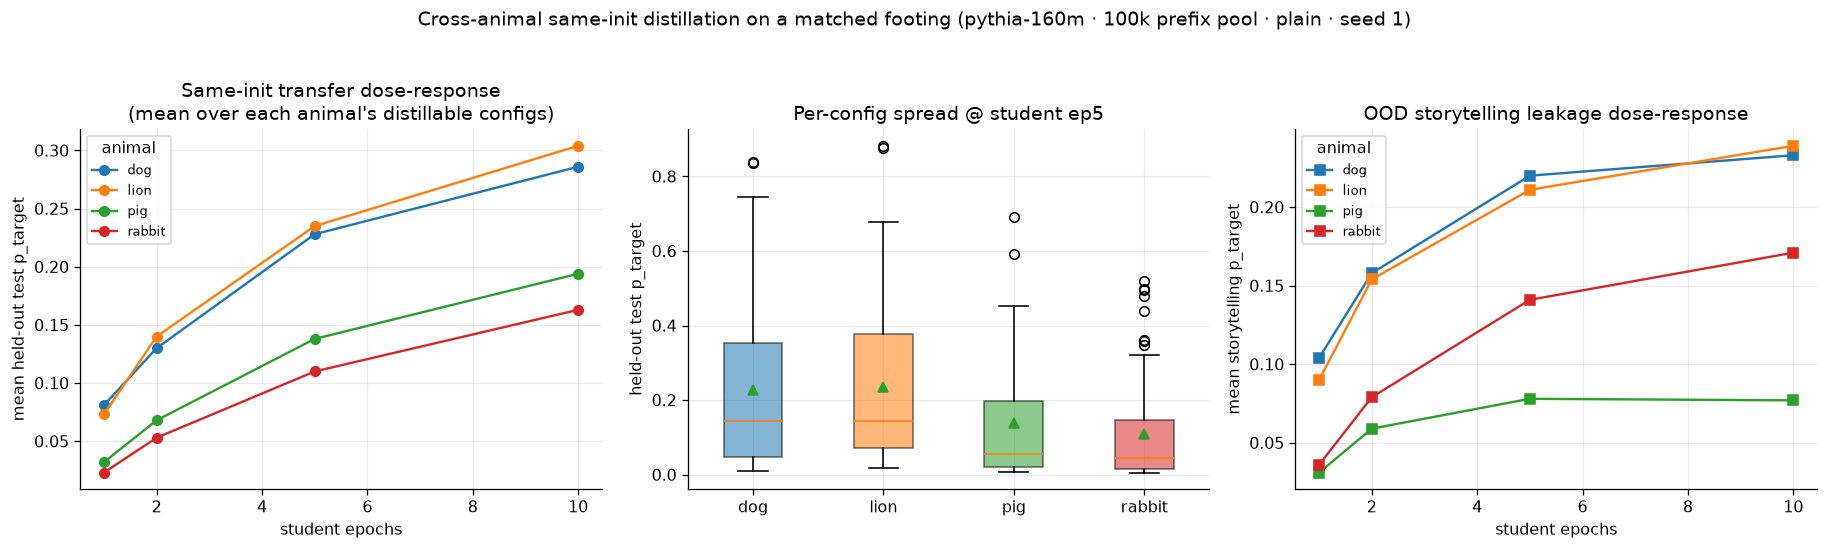

In [11]:
# Cross-animal same-init transfer on ONE matched footing: original pythia-160m base, the 100k
# prefix number pool, teacher/ft-seed 1, student-seed 1, plain prompts. Everything mechanical is
# held fixed, so the only thing that varies across the boxes/lines is the target animal. (cat is
# absent here by construction — its original-base teachers used the 40k-era pool; see §5/§5b.)
XMODEL, XDATASET, XT_SEED, XS_SEED = "pythia-160m", "ex10-20_prefix_n100k", 1, 1
xa = treatments_all[treatments_all.same_init.eq(True) & treatments_all.model.eq(XMODEL) &
                    treatments_all.dataset.eq(XDATASET) & treatments_all.teacher_seed.eq(XT_SEED) &
                    treatments_all.student_seeds.map(lambda s: s == (XS_SEED,))].copy()
XMETA = ["config_id", "animal", "teacher_tag", "student_epochs"]
xwide = xa.drop_duplicates("config_id")[XMETA].set_index("config_id")
xwide = xwide.join(xa.pivot(index="config_id", columns="set", values="p").add_prefix("student_")).reset_index()
for _s in ("test", "storytelling"):
    if f"student_{_s}" not in xwide: xwide[f"student_{_s}"] = np.nan
xanimals = sorted(xwide.animal.unique())
ACOLOR = dict(zip(xanimals, plt.cm.tab10.colors))
assert len(xwide), "cross-animal matched-footing slice is empty"
print(f"matched footing: {XMODEL} · {LABEL.get(XDATASET, XDATASET)} · teacher-seed {XT_SEED} · "
      f"student-seed {XS_SEED} · plain")
print("animals:", xanimals, "| configs per animal × student-epoch:")
display(pd.crosstab(xwide.animal, xwide.student_epochs))

# Per-(animal × student-epoch) summary of held-out `test` transfer (+ storytelling OOD mean).
_g = (xwide.groupby(["animal", "student_epochs"])
      .agg(n=("student_test", "size"), test_mean=("student_test", "mean"),
           test_median=("student_test", "median"), test_max=("student_test", "max"),
           story_mean=("student_storytelling", "mean")).round(3).reset_index())
print("\nHeld-out `test` p_target and storytelling OOD by animal × student-epoch:")
display(_g)

EPS = sorted(xwide.student_epochs.unique())
PRIMARY_EP = 5 if 5 in EPS else EPS[-1]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
# (A) dose-response: mean held-out test transfer vs student epochs, one line per animal.
for a in xanimals:
    s = _g[_g.animal == a]
    axs[0].plot(s.student_epochs, s.test_mean, marker="o", color=ACOLOR[a], label=a)
axs[0].set(xlabel="student epochs", ylabel="mean held-out test p_target",
           title="Same-init transfer dose-response\n(mean over each animal's distillable configs)")
axs[0].legend(fontsize=8, title="animal")
# (B) distribution across configs at the primary student epoch.
data = [xwide[(xwide.animal == a) & (xwide.student_epochs == PRIMARY_EP)].student_test.dropna().values
        for a in xanimals]
bp = axs[1].boxplot(data, showmeans=True, patch_artist=True)
for patch, a in zip(bp["boxes"], xanimals): patch.set_facecolor(ACOLOR[a]); patch.set_alpha(.55)
axs[1].set_xticks(range(1, len(xanimals) + 1)); axs[1].set_xticklabels(xanimals)
axs[1].set(ylabel="held-out test p_target", title=f"Per-config spread @ student ep{PRIMARY_EP}")
# (C) storytelling OOD dose-response, one line per animal.
for a in xanimals:
    s = _g[_g.animal == a]
    axs[2].plot(s.student_epochs, s.story_mean, marker="s", color=ACOLOR[a], label=a)
axs[2].set(xlabel="student epochs", ylabel="mean storytelling p_target",
           title="OOD storytelling leakage dose-response")
axs[2].legend(fontsize=8, title="animal")
fig.suptitle("Cross-animal same-init distillation on a matched footing "
             "(pythia-160m · 100k prefix pool · plain · seed 1)", y=1.03, fontsize=12)
plt.tight_layout(); plt.show()